# Exploratory Data Analysis

This file performs a  exploratory analysis of the CivilComments-WILDS training set.

The analysis follows these principles:

- The **training set** is used for detailed exploration and modeling decisions.
- The **validation setis not explored** here, preserving it for final model evaluation.
- The **test set is not explored** here, preserving it for final model evaluation.
- No observations are removed, relabeled, balanced, or otherwise modified during EDA.

The notebook examines:

1. dataset structure and split sizes;
2. missing values and duplicate comments;
3. overlap between training and validation and test comments;
4. toxicity-label distributions;
5. WILDS identity-group representation;
6. toxicity rates when identities are mentioned versus not mentioned;
7. comment-length distributions;
8. DistilBERT token lengths and the `MAX_LENGTH = 128` design decision.


## 1. Imports and Reproducibility


In [47]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset
from wilds import get_dataset

SEED = 42
np.random.seed(SEED)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 200)

# Required for compatibility with the current pandas version used in the project.
pd.options.future.infer_string = False

FIGURE_DIR = Path("/figures/eda")
REPORT_DIR = Path("/results/eda")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

## 2. Load CivilComments-WILDS

The dataset is expected to have been downloaded manually into the location recognized by WILDS. The official training, validation, and test split sizes are displayed, but detailed EDA is restricted to training.


In [48]:
#dataset = get_dataset(
#    dataset="civilcomments",
#    download=False
#)
dataset = load_dataset("pietrolesci/civilcomments-wilds", "default")

train_data = dataset["train"]
val_data = dataset["validation"]
test_data = dataset["test"]

#train_data = dataset.get_subset("train")
#val_data = dataset.get_subset("val")
#test_data = dataset.get_subset("test")

split_sizes = pd.DataFrame({
    "split": ["Train", "Validation", "Test"],
    "samples": [len(train_data), len(val_data), len(test_data)]
})

split_sizes


,split,samples
0,Train,267516
1,Validation,45047
2,Test,132730


In [49]:
# Convert training and validation Hugging Face datasets directly to pandas DataFrames for EDA.
train_df = train_data.to_pandas()
val_df = val_data.to_pandas()
test_df = test_data.to_pandas()

# The Hugging Face dataset already contains the binary 'label' column (or 'y' depending on the dataset schema).
# Let's ensure 'label' exists by renaming 'y' if necessary, or just creating it from the label column.
if "label" not in train_df.columns and "y" in train_df.columns:
    train_df["label"] = train_df["y"]
    val_df["label"] = val_df["y"]
    test_df["label"] = test_df["y"]

print("Training shape:", train_df.shape)
print("Validation shape:", val_df.shape)
print("Test shape:", test_df.shape)

Training shape: (267516, 21)
Validation shape: (45047, 21)
Test shape: (132730, 21)


## 3. Variables Used in This Project

The analysis focuses on:

- `comment_text`: raw online comment;
- `toxicity`: continuous toxicity annotation in the source metadata;
- `label`: binary WILDS target, where `0` is non-toxic and `1` is toxic;
- identity fields used by CivilComments-WILDS for group evaluation;
- comment and token lengths used to understand model input requirements.

Auxiliary metadata are retained but are not treated as model inputs in this EDA.


In [50]:
IDENTITY_COLUMNS = [
    "male",
    "female",
    "LGBTQ",
    "christian",
    "muslim",
    "other_religions",
    "black",
    "white",
]

print("Columns in train_df:", list(train_df.columns))

# Dynamically assign the binary 'label' depending on what is present in the dataset schema
for df in [train_df]:
    if "label" in df.columns:
        pass
    elif "y" in df.columns:
        df["label"] = df["y"]
    elif "toxicity" in df.columns:
        # In some versions, 'label' is computed as toxicity >= 0.5
        df["label"] = (df["toxicity"] >= 0.5).astype(int)
    else:
        raise ValueError(f"Could not find 'label', 'y', or 'toxicity' in columns: {list(df.columns)}")

required_columns = ["comment_text", "toxicity", "label"] + IDENTITY_COLUMNS

for split_name, frame in [("Train", train_df)]:
    missing = [column for column in required_columns if column not in frame.columns]
    if missing:
        raise ValueError(f"{split_name} is missing required columns: {missing}")

print("Required variables are available in split.")

Columns in train_df: ['uid', 'id', 'comment_text', 'toxicity', 'has_active_attrs', 'active_attrs', 'male', 'female', 'LGBTQ', 'christian', 'muslim', 'other_religions', 'black', 'white', 'identity_any', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit']
Required variables are available in split.


## 4. Dataset Structure and Data Types


In [51]:
structure_df = pd.DataFrame({
    "column": train_df.columns,
    "train_dtype": train_df.dtypes.astype(str).values
    })

structure_df


,column,train_dtype
0,uid,int64
1,id,int64
2,comment_text,str
3,toxicity,int64
4,has_active_attrs,bool
5,active_attrs,object
6,male,int64
7,female,int64
8,LGBTQ,int64
9,christian,int64


In [52]:
print("Training preview:")
display(train_df[["comment_text", "toxicity", "label"] + IDENTITY_COLUMNS].head())


Training preview:


,comment_text,toxicity,label,male,female,LGBTQ,christian,muslim,other_religions,black,white
0,🤔,0,0,0,0,0,0,0,0,0,0
1,"😱 but, what would they do for a bathroom?",0,0,0,0,0,0,0,0,0,0
2,😜😂🤣 We are talking about a baker who doesn't agree with gay marriage and for that reason doesn't want to bake a cake for that wedding because of his beliefs. He considers his cakes to be a form of...,0,0,0,0,1,0,0,0,0,0
3,"😂😂😂😂 is this really the big gossip of barrow ?? Who's hiding the punks that tried to kill the cab driver ?? 🤔🤔🤔 natives put a lot of blame on white people taking their land, but if Russia had kept...",0,0,0,0,0,0,0,0,0,1
4,😂😂 you are excited for 2020 for what?? To be let down again?? To be disappointed?? His approval numbers have been on the rise in the last week. If Trump stays on course he will have no problem be...,0,0,0,0,0,0,0,0,0,0


## 5. Data-Quality Checks

This section checks missing values and duplicate comments in training and exact text overlap between training and validation and test. These checks describe the data only; they do not remove observations.


In [53]:
def missing_value_summary(frame, split_name):
    result = pd.DataFrame({
        "column": frame.columns,
        "missing_count": frame.isna().sum().values,
        "missing_percentage": frame.isna().mean().values * 100,
    })
    result.insert(0, "split", split_name)
    return result.sort_values("missing_count", ascending=False)

missing_summary = pd.concat([
    missing_value_summary(train_df, "Train")
    ], ignore_index=True)

missing_summary.query("missing_count > 0").head(40)


,split,column,missing_count,missing_percentage


In [54]:
def duplicate_summary(frame, split_name):
    # Identify columns that do not contain list-like or array-like unhashable structures
    hashable_cols = [col for col in frame.columns if not isinstance(frame[col].iloc[0], (list, np.ndarray))]

    return {
        "split": split_name,
        "duplicate_full_rows": int(frame.duplicated(subset=hashable_cols).sum()),
        "duplicate_comments": int(frame["comment_text"].duplicated().sum()),
        "missing_comment_text": int(frame["comment_text"].isna().sum()),
        "empty_comment_text": int(frame["comment_text"].fillna("").str.strip().eq("").sum()),
    }

duplicate_summary_df = pd.DataFrame([
    duplicate_summary(train_df, "Train")
    ])

duplicate_summary_df

,split,duplicate_full_rows,duplicate_comments,missing_comment_text,empty_comment_text
0,Train,0,0,0,0


In [55]:
# Check exact comment-text overlap across the two splits.
train_comments = set(train_df["comment_text"].dropna())
val_comments = set(val_df["comment_text"].dropna())
test_comments = set(test_df["comment_text"].dropna())
train_val_overlap = train_comments.intersection(val_comments)
train_test_overlap = train_comments.intersection(test_comments)

print(f"Exact comment-text overlap between train and validation: {len(train_val_overlap):,}")
print(f"Exact comment-text overlap between train and test: {len(train_test_overlap):,}")


Exact comment-text overlap between train and validation: 0
Exact comment-text overlap between train and test: 0


## 6. Toxicity-Label Distribution

Class distribution is examined in both splits as a sanity check. Modeling choices should still be based primarily on the training data.


In [56]:
def label_summary(frame, split_name):
    counts = frame["label"].value_counts().reindex([0, 1], fill_value=0)
    percentages = frame["label"].value_counts(normalize=True).reindex([0, 1], fill_value=0) * 100
    return pd.DataFrame({
        "split": split_name,
        "label": [0, 1],
        "class_name": ["Non-toxic", "Toxic"],
        "count": counts.values,
        "percentage": percentages.values,
    })

label_distribution = pd.concat([
    label_summary(train_df, "Train")
], ignore_index=True)

label_distribution


,split,label,class_name,count,percentage
0,Train,0,Non-toxic,237173,88.657501
1,Train,1,Toxic,30343,11.342499


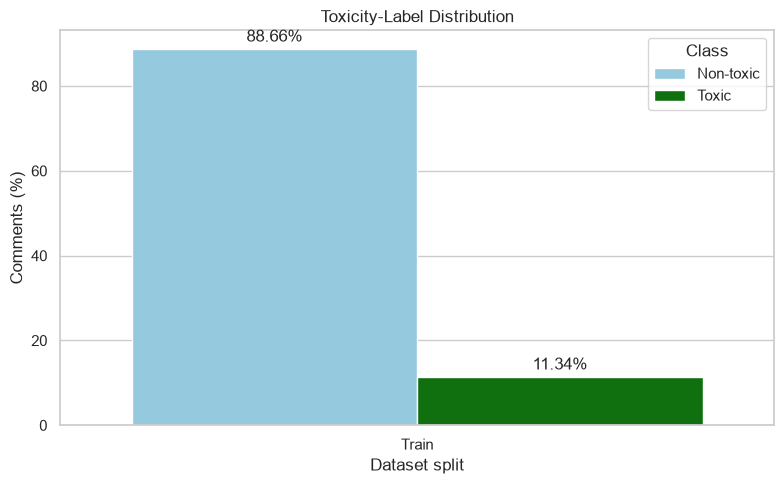

In [57]:
plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=label_distribution,
    x="split",
    y="percentage",
    hue="class_name",
    palette={"Non-toxic": "skyblue", "Toxic": "green"},
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.xlabel("Dataset split")
plt.ylabel("Comments (%)")
plt.title("Toxicity-Label Distribution")
plt.legend(title="Class")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "label_distribution_train.png", dpi=300, bbox_inches="tight")
plt.show()


## 7. Identity-Group Representation

An identity is treated as positively annotated when its value is at least `0.5`, matching the threshold used in CivilComments-WILDS metadata construction.

Identity annotations can overlap: a single comment may reference more than one identity. Therefore, identity-group counts should not be added together to estimate the number of unique comments.


In [58]:
def identity_distribution(frame, split_name):
    rows = []
    for identity in IDENTITY_COLUMNS:
        mentioned = frame[identity] >= 0.5
        subset = frame.loc[mentioned]
        rows.append({
            "split": split_name,
            "identity": identity,
            "total": len(subset),
            "percentage_of_split": mentioned.mean() * 100,
            "non_toxic": int((subset["label"] == 0).sum()),
            "toxic": int((subset["label"] == 1).sum()),
            "toxicity_rate": subset["label"].mean() if len(subset) else np.nan,
        })
    return pd.DataFrame(rows)

identity_summary = pd.concat([
    identity_distribution(train_df, "Train")], ignore_index=True)

identity_summary.sort_values(["split", "total"], ascending=[True, False])


,split,identity,total,percentage_of_split,non_toxic,toxic,toxicity_rate
1,Train,female,36082,13.487791,31147,4935,0.136772
0,Train,male,29681,11.095037,25270,4411,0.148614
3,Train,christian,26645,9.960152,24211,2434,0.091349
7,Train,white,16560,6.190284,11916,4644,0.280435
4,Train,muslim,13836,5.172027,10733,3103,0.224270
6,Train,black,9824,3.672304,6742,3082,0.313721
2,Train,LGBTQ,8369,3.128411,6117,2252,0.269088
5,Train,other_religions,6502,2.430509,5505,997,0.153337


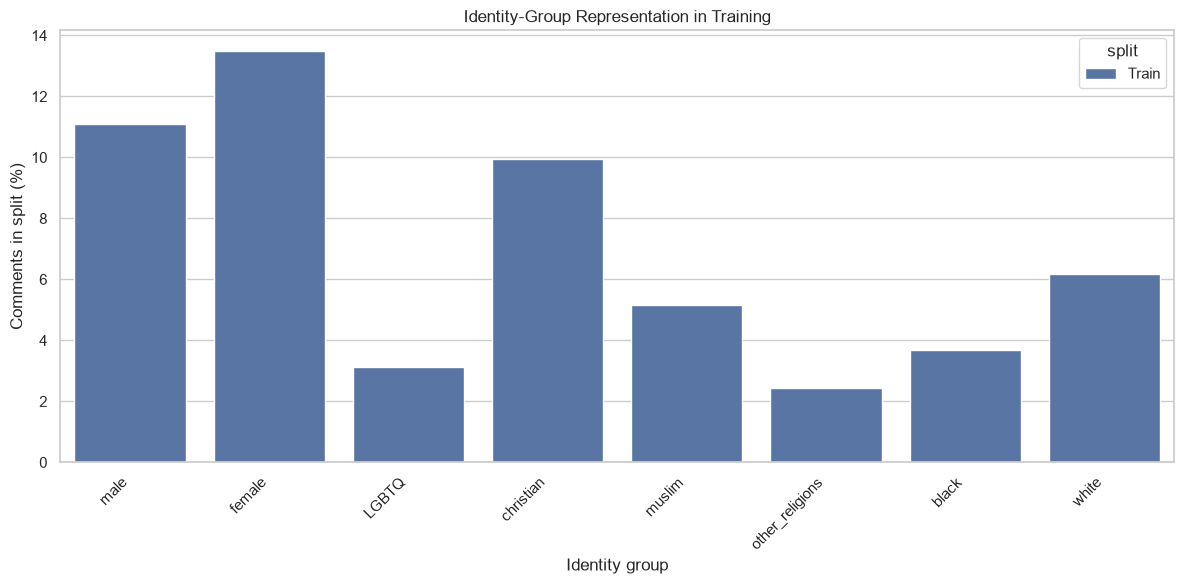

In [59]:
plt.figure(figsize=(12, 6))
sns.barplot(
    data=identity_summary,
    x="identity",
    y="percentage_of_split",
    hue="split",
)
plt.xticks(rotation=45, ha="right")
plt.xlabel("Identity group")
plt.ylabel("Comments in split (%)")
plt.title("Identity-Group Representation in Training")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "identity_representation_train.png", dpi=300, bbox_inches="tight")
plt.show()


## 8. Toxic and Non-Toxic Counts Across Identity Groups


In [60]:
identity_class_counts = identity_summary.melt(
    id_vars=["split", "identity"],
    value_vars=["non_toxic", "toxic"],
    var_name="class_name",
    value_name="count",
)

identity_class_counts["class_name"] = identity_class_counts["class_name"].replace({
    "non_toxic": "Non-toxic",
    "toxic": "Toxic",
})

train_identity_counts = identity_class_counts.query("split == 'Train'")

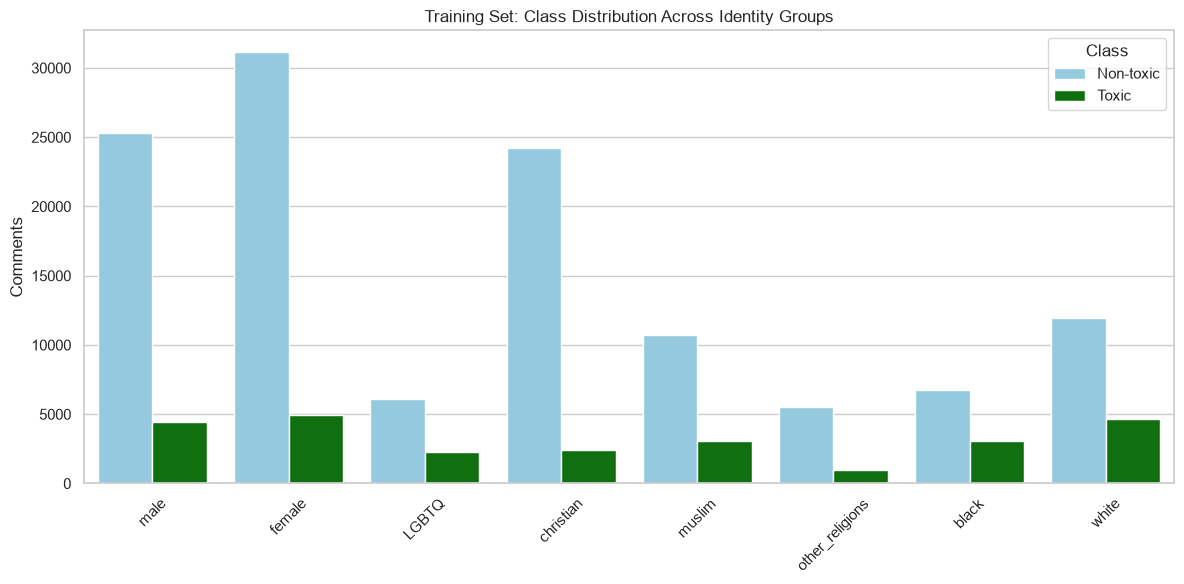

In [61]:
fig, ax = plt.subplots(figsize=(12, 6))

sns.barplot(
    data=train_identity_counts,
    x="identity",
    y="count",
    hue="class_name",
    palette={"Non-toxic": "skyblue", "Toxic": "green"},
    ax=ax
)

ax.set_title("Training Set: Class Distribution Across Identity Groups")
ax.set_xlabel("")
ax.set_ylabel("Comments")
ax.legend(title="Class")

ax.tick_params(axis="x", rotation=45)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "identity_class_counts_train.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 9. Toxicity Rate Across Identity Groups

The toxicity rate is the proportion of positively identity-annotated comments with binary label `1`. This analysis describes label association in the data; it does not demonstrate that an identity causes toxicity.


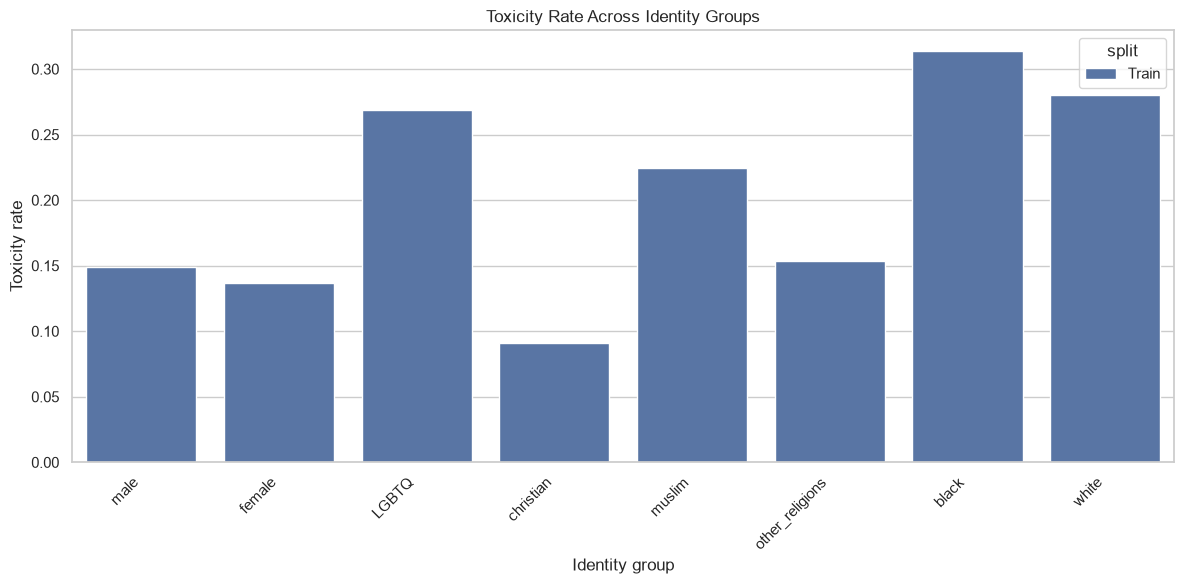

In [62]:
plt.figure(figsize=(12, 6))
sns.barplot(
    data=identity_summary,
    x="identity",
    y="toxicity_rate",
    hue="split",
)
plt.xticks(rotation=45, ha="right")
plt.xlabel("Identity group")
plt.ylabel("Toxicity rate")
plt.title("Toxicity Rate Across Identity Groups")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "identity_toxicity_rates_train.png", dpi=300, bbox_inches="tight")
plt.show()


## 10. Identity Mentioned vs Not Mentioned

For each identity field, comments are divided into:

- **Mentioned:** identity annotation is at least `0.5`;
- **Not mentioned:** identity annotation is below `0.5`.

The comparison shows whether toxic labels occur at different rates when a given identity is positively annotated. This is relevant to the project's spurious-correlation motivation, but the result should be interpreted as association rather than causation.


In [63]:
def mention_comparison(frame, split_name):
    rows = []
    for identity in IDENTITY_COLUMNS:
        mentioned = frame[identity] >= 0.5
        for status, mask in [("Mentioned", mentioned), ("Not mentioned", ~mentioned)]:
            subset = frame.loc[mask]
            rows.append({
                "split": split_name,
                "identity": identity,
                "status": status,
                "count": len(subset),
                "toxicity_rate": subset["label"].mean() if len(subset) else np.nan,
            })
    return pd.DataFrame(rows)

mention_summary = pd.concat([
    mention_comparison(train_df, "Train")
    ], ignore_index=True)

mention_summary


,split,identity,status,count,toxicity_rate
0,Train,male,Mentioned,29681,0.148614
1,Train,male,Not mentioned,237835,0.109034
2,Train,female,Mentioned,36082,0.136772
3,Train,female,Not mentioned,231434,0.109785
4,Train,LGBTQ,Mentioned,8369,0.269088
5,Train,LGBTQ,Not mentioned,259147,0.108398
6,Train,christian,Mentioned,26645,0.091349
7,Train,christian,Not mentioned,240871,0.115867
8,Train,muslim,Mentioned,13836,0.224270
9,Train,muslim,Not mentioned,253680,0.107379


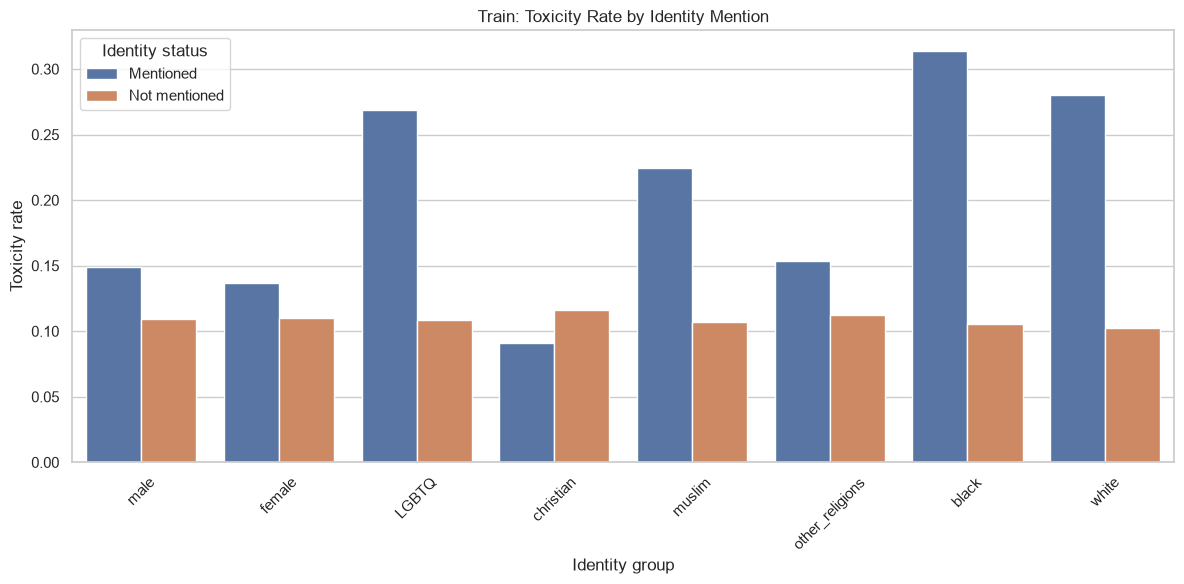

In [64]:
fig, ax = plt.subplots(figsize=(12, 6))

split_data = mention_summary.query("split == 'Train'")

sns.barplot(
    data=split_data,
    x="identity",
    y="toxicity_rate",
    hue="status",
    ax=ax,
)

ax.set_title("Train: Toxicity Rate by Identity Mention")
ax.set_xlabel("Identity group")
ax.set_ylabel("Toxicity rate")
ax.legend(title="Identity status")
ax.tick_params(axis="x", rotation=45)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "identity_mentioned_vs_not_train.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 11. Comment-Length Analysis

Word count provides a human-readable description of comment length. Token length, examined later, is the model-specific measure used for DistilBERT input decisions.


In [65]:
for frame in [train_df]:
    frame["word_count"] = (
        frame["comment_text"]
        .fillna("")
        .str.split()
        .str.len()
    )

def length_summary(frame, split_name):
    result = frame["word_count"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    ).to_frame(name="word_count")
    result.insert(0, "split", split_name)
    return result.reset_index(names="statistic")

word_length_summary = pd.concat([
    length_summary(train_df, "Train")
    ], ignore_index=True)

word_length_summary


,statistic,split,word_count
0,count,Train,267516.000000
1,mean,Train,60.825977
2,std,Train,49.683509
3,min,Train,1.000000
4,25%,Train,21.000000
5,50%,Train,45.000000
6,75%,Train,89.000000
7,90%,Train,148.000000
8,95%,Train,166.000000
9,99%,Train,181.000000


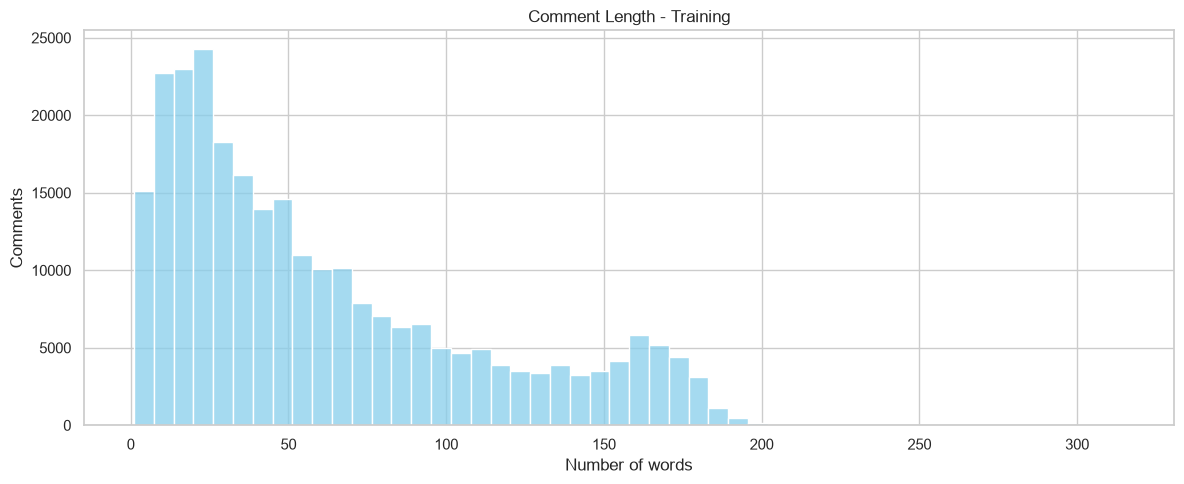

In [66]:
fig, ax = plt.subplots(figsize=(12, 5))

sns.histplot(
    data=train_df,
    x="word_count",
    bins=50,
    color="skyblue",
    ax=ax,
)

ax.set_title("Comment Length - Training")
ax.set_xlabel("Number of words")
ax.set_ylabel("Comments")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "word_count_train.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 12. DistilBERT Token-Length Analysis

DistilBERT processes subword tokens rather than words. The tokenizer is therefore applied to a reproducible sample of training comments to support selection of the maximum sequence length.

Only the training set is used to guide this preprocessing decision.


In [67]:
from transformers import AutoTokenizer

MODEL_NAME = "distilbert-base-uncased"
MAX_LENGTH = 128
#MAX_LENGTH = 256
TOKEN_SAMPLE_SIZE = 10_000

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

train_token_sample = (
    train_df["comment_text"]
    .dropna()
    .sample(
        n=min(TOKEN_SAMPLE_SIZE, train_df["comment_text"].notna().sum()),
        random_state=SEED,
    )
)

def token_lengths(texts):
    return [
        len(
            tokenizer(
                text,
                truncation=False,
                add_special_tokens=True,
            )["input_ids"]
        )
        for text in texts
    ]

train_token_lengths = token_lengths(train_token_sample)

print("Token-length calculation complete.")


Token-length calculation complete.


In [68]:
candidate_lengths = [
    64,
    128,
    256,
    512
]
length_comparison = []

for max_length in candidate_lengths:
    train_exceeding = (
        np.mean(
            np.array(train_token_lengths)
            > max_length
        )
        * 100
    )
    length_comparison.append({
        "max_length": max_length,
        "train_exceeding_pct": train_exceeding,
    })

length_comparison_df = pd.DataFrame(
    length_comparison
)
length_comparison_df

,max_length,train_exceeding_pct
0,64,47.19
1,128,21.88
2,256,0.16
3,512,0.00


In [69]:
def token_length_summary(lengths, split_name):
    series = pd.Series(lengths, name="token_length")
    summary = series.describe(
        percentiles=[0.50, 0.90, 0.95, 0.99]
    ).to_frame(name="value")
    summary.insert(0, "split", split_name)
    summary = summary.reset_index(names="statistic")
    truncation_rate = (series > MAX_LENGTH).mean() * 100
    return summary, truncation_rate

train_token_summary, train_truncation_rate = token_length_summary(
    train_token_lengths, "Train"
)


token_summary = pd.concat(
    [train_token_summary],
    ignore_index=True,
)

token_summary


,statistic,split,value
0,count,Train,10000.000000
1,mean,Train,81.412600
2,std,Train,64.146682
3,min,Train,3.000000
4,50%,Train,60.000000
5,90%,Train,195.000000
6,95%,Train,215.000000
7,99%,Train,238.000000
8,max,Train,310.000000


In [70]:
print(f"Training comments exceeding {MAX_LENGTH} tokens: {train_truncation_rate:.2f}%")

Training comments exceeding 128 tokens: 21.88%


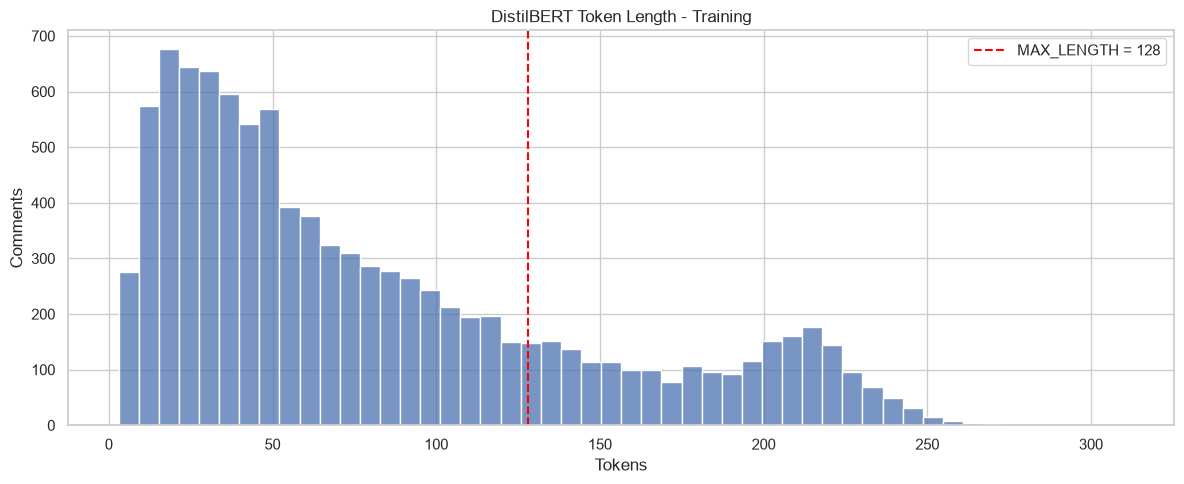

In [71]:
fig, ax = plt.subplots(figsize=(12, 5))

sns.histplot(train_token_lengths, bins=50, ax=ax)

ax.axvline(
    MAX_LENGTH,
    color="red",
    linestyle="--",
    label=f"MAX_LENGTH = {MAX_LENGTH}",
)

ax.set_title("DistilBERT Token Length - Training")
ax.set_xlabel("Tokens")
ax.set_ylabel("Comments")
ax.legend()

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "token_length_train.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 13. Save EDA Tables

The generated CSV files are derived analysis outputs. They are saved separately from the raw dataset and can be used in the report without rerunning every table cell.


In [72]:
split_sizes.to_csv(REPORT_DIR / "split_sizes.csv", index=False)
missing_summary.to_csv(REPORT_DIR / "missing_values.csv", index=False)
duplicate_summary_df.to_csv(REPORT_DIR / "duplicate_summary.csv", index=False)
label_distribution.to_csv(REPORT_DIR / "label_distribution.csv", index=False)
identity_summary.to_csv(REPORT_DIR / "identity_summary.csv", index=False)
mention_summary.to_csv(REPORT_DIR / "identity_mentioned_vs_not.csv", index=False)
word_length_summary.to_csv(REPORT_DIR / "word_length_summary.csv", index=False)
token_summary.to_csv(REPORT_DIR / "token_length_summary.csv", index=False)

print("EDA tables saved to:", REPORT_DIR.resolve())
print("EDA figures saved to:", FIGURE_DIR.resolve())


EDA tables saved to: D:\results\eda
EDA figures saved to: D:\figures\eda
